In [1]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras import models,layers
import matplotlib.pyplot as plt
import glob
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

In [2]:
IMAGE_SIZE=256
BATCH_SIZE=32
CHANNELS=3
EPOCHS=50
INPUT_SHAPE = (BATCH_SIZE , IMAGE_SIZE , IMAGE_SIZE , CHANNELS)

In [3]:
dataset = tf.keras.preprocessing.image_dataset_from_directory(
    directory="../Dataset/archive/PlantVillage",
    shuffle=True,
    image_size=(IMAGE_SIZE,IMAGE_SIZE),
    batch_size=BATCH_SIZE,
)

Found 2152 files belonging to 3 classes.


In [4]:
class_names = dataset.class_names
classes_number = len(class_names)
print("Classes names : \n" , class_names)
print("Classes number : \n" , classes_number)

Classes names : 
 ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']
Classes number : 
 3


In [5]:
# the length of the dataset is not 68 images, the length is 68 batches each batch has a batch size except the last one it may be less or more
len(dataset)

68

In [6]:
for image_batch , label_batch in dataset.take(1):
    print(image_batch.shape)
    print(label_batch.numpy())

(32, 256, 256, 3)
[0 1 1 0 1 1 1 0 1 1 1 0 0 0 1 0 0 0 1 2 1 0 0 1 0 0 0 2 0 0 1 0]


In [1]:
plt.figure(figsize=(10,10))
for image_batch , label_batch in dataset.take(1):
    for i in range(12):
        ax = plt.subplot(3,4,i+1)
        plt.imshow(image_batch[i].numpy().astype("uint8"))
        plt.axis("off")
        plt.title(class_names[label_batch[i].numpy()])

NameError: name 'plt' is not defined

## Dataset splitting 

**we will split the dataset as follow:**<br>
80% of the dataset ==>training<br>
10% of the dataset ==>validation<br>
10% of the dataset ==>testing

In [8]:
train_size = 0.8
validation_size = 0.1
test_size = 0.1

In [9]:
train_ds = dataset.take(int(len(dataset)*train_size))

In [10]:
len(train_ds)

54

In [11]:
test_ds = dataset.skip(len(train_ds))
len(test_ds)

14

In [12]:
validation_ds = test_ds.take(6)
len(validation_ds)

6

In [13]:
test_ds = test_ds.skip(len(validation_ds))
len(test_ds)

8

In [14]:
print("Size of the training dataset : " , len(train_ds))
print("Size of the validation dataset : " , len(validation_ds))
print("Size of the testing dataset : " , len(test_ds))

Size of the training dataset :  54
Size of the validation dataset :  6
Size of the testing dataset :  8


In [15]:
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size = tf.data.AUTOTUNE)
validation_ds = validation_ds.cache().shuffle(1000).prefetch(buffer_size = tf.data.AUTOTUNE)
test_ds = test_ds.cache().shuffle(1000).prefetch(buffer_size = tf.data.AUTOTUNE)

#### **Now it's time for scaling and resizing**
we will build tesnorflow scaling layer, and apply it later <br>
**note :** we have actually resize the images when we load the dataset previously, but the following resizing is the best practice to handle errors, exceptions , and etc... 

In [16]:
resizing_scaling_layer = tf.keras.Sequential([
    # this layer is for resizing
    layers.experimental.preprocessing.Resizing(IMAGE_SIZE,IMAGE_SIZE),
    # this layer is for Rescaling
    layers.experimental.preprocessing.Rescaling(1.0/255)
])

#### **Now it's time for Data Augmentation**
we will use the following augmentation for our data set :<br>
**1- Randomflib** ==> randomly flib images horizontaly/verticaly <br>
**2- RandomRotation** ==> randomly rotate images 0.2 fraction<br>
**3- RandomContrast** ==> randomly flib images 0.2 fraction <br>

In [17]:
data_augmentation_layer = tf.keras.Sequential([
    layers.experimental.preprocessing.RandomFlip('horizontal_and_vertical'),
    layers.experimental.preprocessing.RandomRotation(0.2),
    layers.experimental.preprocessing.RandomContrast(0.2)
])

#### **Model Training**

In [2]:
model = tf.keras.Sequential([
    resizing_scaling_layer,
    data_augmentation_layer,
    layers.Conv2D(filters= 32 , kernel_size=(3,3) , input_shape=INPUT_SHAPE , activation="relu"),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(filters= 64 , kernel_size=(3,3) ,  activation="relu"),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(filters= 64 , kernel_size=(3,3) , activation="relu"),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(filters= 64 , kernel_size=(3,3)  , activation="relu"),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(filters= 64 , kernel_size=(3,3) ,  activation="relu"),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(filters= 64 , kernel_size=(3,3) ,  activation="relu"),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(64 , activation = "relu"),
    layers.Dense(classes_number , activation = "softmax"),
])

NameError: name 'tf' is not defined

In [21]:
model.build(input_shape=INPUT_SHAPE)

In [22]:
model.summary()

Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 sequential (Sequential)     (32, 256, 256, 3)         0         
                                                                 
 sequential_1 (Sequential)   (None, 256, 256, 3)       0         
                                                                 
 conv2d_12 (Conv2D)          (None, 254, 254, 32)      896       
                                                                 
 max_pooling2d_12 (MaxPoolin  (None, 127, 127, 32)     0         
 g2D)                                                            
                                                                 
 conv2d_13 (Conv2D)          (None, 125, 125, 64)      18496     
                                                                 
 max_pooling2d_13 (MaxPoolin  (None, 62, 62, 64)       0         
 g2D)                                                 

In [23]:
model.compile(
    optimizer = "adam",
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

In [27]:
history =  model.fit(
    x = train_ds,
    verbose = 1,
    batch_size = BATCH_SIZE,
    validation_data=validation_ds,
    epochs=EPOCHS
)

Epoch 1/50
54/54 [==============================] - 30s 396ms/step - loss: 0.8421 - accuracy: 0.5532 - val_loss: 0.7450 - val_accuracy: 0.6250
Epoch 2/50
54/54 [==============================] - 20s 378ms/step - loss: 0.5423 - accuracy: 0.7500 - val_loss: 0.4800 - val_accuracy: 0.8229
Epoch 3/50
54/54 [==============================] - 20s 374ms/step - loss: 0.3886 - accuracy: 0.8339 - val_loss: 0.3006 - val_accuracy: 0.8542
Epoch 4/50
54/54 [==============================] - 20s 375ms/step - loss: 0.2901 - accuracy: 0.8900 - val_loss: 0.3460 - val_accuracy: 0.8281
Epoch 5/50
54/54 [==============================] - 21s 387ms/step - loss: 0.2522 - accuracy: 0.8964 - val_loss: 0.1848 - val_accuracy: 0.9427
Epoch 6/50
54/54 [==============================] - 21s 382ms/step - loss: 0.2157 - accuracy: 0.9149 - val_loss: 0.1713 - val_accuracy: 0.9375
Epoch 7/50
54/54 [==============================] - 20s 376ms/step - loss: 0.1954 - accuracy: 0.9288 - val_loss: 0.2528 - val_accuracy: 0.8906

In [28]:
scores = model.evaluate(test_ds)

8/8 [==============================] - 2s 52ms/step - loss: 0.2767 - accuracy: 0.9181


In [29]:
scores

[0.27666881680488586, 0.9181034564971924]

In [33]:
history.params

{'verbose': 1, 'epochs': 50, 'steps': 54}

In [43]:
history.history.keys()

dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])

In [46]:
print("Miximum Accuracy : \n" ,max(history.history['accuracy']))
print("Miximum validation Accuracy : \n" ,max(history.history['val_accuracy']))
print("Minimum loss : \n" ,min(history.history['loss']))
print("Minimum loss : \n" ,min(history.history['val_loss']))


Miximum Accuracy : 
 0.9953703880310059
Miximum validation Accuracy : 
 0.9947916865348816
Minimum loss : 
 0.01519362535327673
Minimum loss : 
 0.03525673225522041


In [47]:
accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

Text(0.5, 1.0, 'Training and Validation loss')

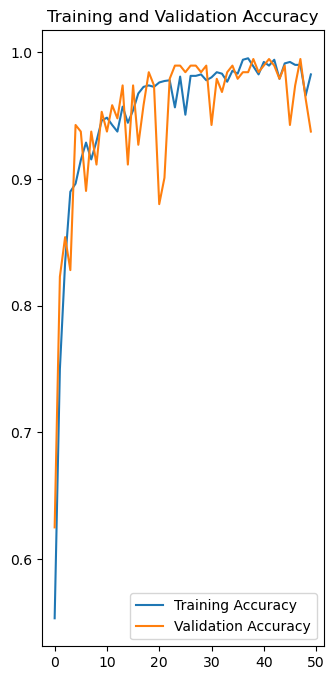

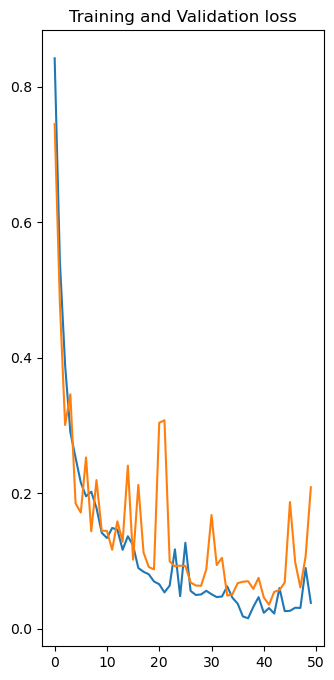

In [64]:
plt.figure(figsize=(8,8))
plt.subplot(1,2,1)
plt.plot(range(EPOCHS) , accuracy , label="Training Accuracy")
plt.plot(range(EPOCHS) , val_accuracy , label="Validation Accuracy")
plt.legend(loc="lower right")
plt.title("Training and Validation Accuracy")

plt.figure(figsize=(8,8))
plt.subplot(1,2,2)
plt.plot(range(EPOCHS) , loss , label="Training loss")
plt.plot(range(EPOCHS) , val_loss , label="Validation loss")
# plt.legend(loc="lower right")
plt.title("Training and Validation loss")

first image to predict :
Actual label :  Potato___Early_blight
predicted label Potato___Early_blight


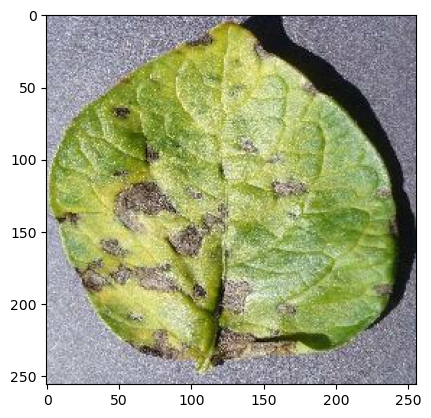

In [91]:
for image_batch , image_label in test_ds.take(1):
    first_image = image_batch[0].numpy().astype("uint8")
    first_label = image_label[0].numpy()
    print("first image to predict :")
    plt.imshow(image_batch[0].numpy().astype("uint8"))
    print("Actual label : " , class_names[first_label])
    batch_prediction = model.predict(image_batch , verbose=0)
    print("predicted label" , class_names[np.argmax(batch_prediction[0])])

In [108]:
def predict(model , img):
    img_array = tf.keras.preprocessing.image.img_to_array(img)
    img_array = tf.expand_dims(img_array , 0)

    predictions = model.predict(img_array , verbose=0)
    predicted_class = class_names[np.argmax(predictions[0])]
    confidence = round(100 * (np.max(predictions[0])) , 2)
    return predicted_class , confidence

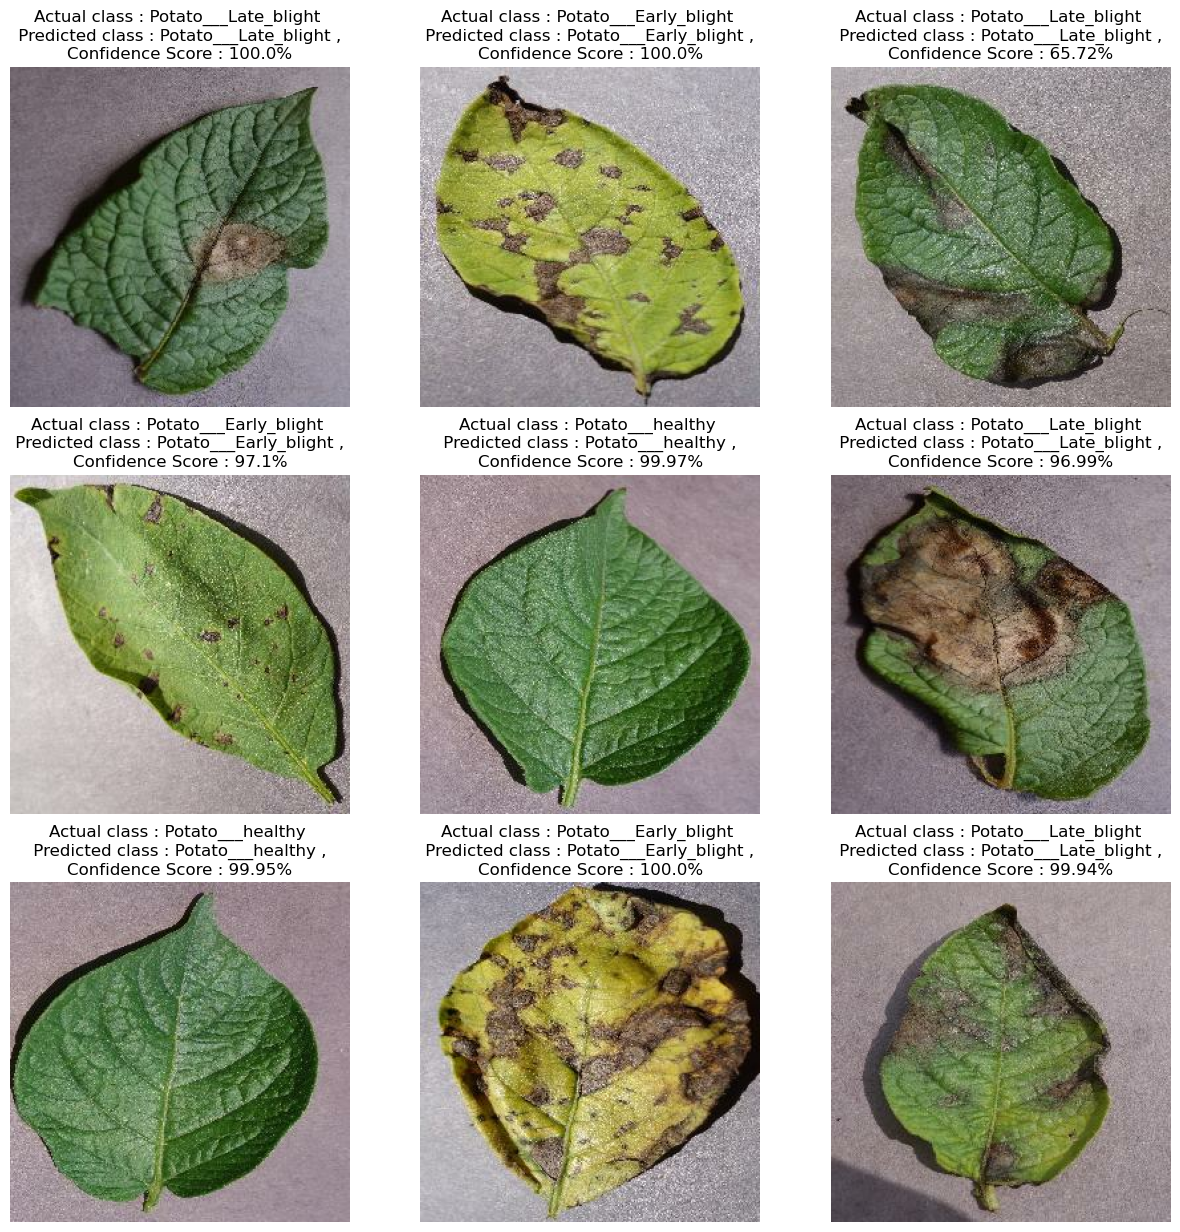

In [196]:
plt.figure(figsize=(15 , 15))
for image , label in test_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3 , 3 , i+1)
        plt.imshow(image[i].numpy().astype("uint8"))
        plt.axis("off")
        predicted_classes , confidence = predict(model , image[i].numpy())
        actual_class = class_names[label[i]]
        plt.title(f"Actual class : {actual_class} \n Predicted class : {predicted_classes} , \nConfidence Score : {confidence}%")

In [ ]:
model_version = 1 
model.save(f"../Models/model_version_{model_version}")